In [26]:
import torch
import matplotlib.pyplot as plt

class BSplineBasis1D:
    def __init__(self, h, p, C, device=None, dtype=torch.float64):
        self.h = int(h)
        self.p = int(p)
        self.C = int(C)
        self.device = device or torch.device("cpu")
        self.dtype = dtype
        self.eps = 1e-12

        start = torch.zeros(p + 1, dtype=dtype, device=self.device)
        end = torch.ones(p + 1, dtype=dtype, device=self.device)
        inner = torch.linspace(0, 1, int((h - p - 1) / (p - C)) + 2,
                               dtype=dtype, device=self.device)[1:-1]
        self.knot_vector = torch.cat([start, inner.repeat_interleave(p - C), end])

    def _basis_matrix(self, x, degree):
        """Vectorized iterative Cox–de Boor up to 'degree'."""
        kv, h, eps = self.knot_vector, self.h, self.eps
        x = x.to(self.device).to(self.dtype).reshape(-1)
        n = x.numel()

        # degree 0
        kv0 = kv[:-1]; kv1 = kv[1:]
        N = ((x[:, None] >= kv0) & (x[:, None] < kv1)).to(self.dtype)
        # include right end for the very last basis only
        N[:, -1] |= (x[:, None] == kv1[-1])

        # elevate degree iteratively
        for d in range(1, degree + 1):
            left_denom = kv[d:h + d] - kv[:h]
            right_denom = kv[d + 1:h + d + 1] - kv[1:h + 1]
            left_num = x[:, None] - kv[:h]
            right_num = kv[d + 1:h + d + 1] - x[:, None]
            left = torch.where(left_denom.abs() > eps, left_num / left_denom, torch.zeros_like(left_num))
            right = torch.where(right_denom.abs() > eps, right_num / right_denom, torch.zeros_like(right_num))
            term1 = left * N
            term2 = torch.zeros_like(N)
            term2[:, :-1] = right[:, :-1] * N[:, 1:]
            N = term1 + term2
        return N

    def forward(self, x):  # basis matrix
        return self._basis_matrix(x, self.p)

    def grad(self, x):  # derivative matrix
        if self.p == 0:
            return torch.zeros((x.numel(), self.h), device=self.device, dtype=self.dtype)
        kv = self.knot_vector
        Npm1 = self._basis_matrix(x, self.p - 1)
        denom1 = kv[self.p:self.h + self.p] - kv[:self.h]
        denom2 = kv[self.p + 1:self.h + self.p + 1] - kv[1:self.h + 1]
        inv1 = torch.where(denom1.abs() > self.eps, 1.0 / denom1, torch.zeros_like(denom1))
        inv2 = torch.where(denom2.abs() > self.eps, 1.0 / denom2, torch.zeros_like(denom2))
        part1 = Npm1 * inv1[None, :]
        part2 = torch.zeros_like(Npm1)
        part2[:, :-1] = Npm1[:, 1:] * inv2[None, :-1]
        return self.p * (part1 - part2)

    # simple plotting helpers
    def plot_1d_basis(self, res=1000):
        x = torch.linspace(self.knot_vector[self.p], self.knot_vector[-self.p-1], res)
        N = self.forward(x).cpu()
        plt.figure(); [plt.plot(x, N[:,i]) for i in range(self.h)]
        plt.title("B-spline basis"); plt.grid(); plt.show()

    def plot_1d_basis_gradients(self, res=1000):
        x = torch.linspace(self.knot_vector[self.p], self.knot_vector[-self.p-1], res)
        dN = self.grad(x).cpu()
        plt.figure(); [plt.plot(x, dN[:,i]) for i in range(self.h)]
        plt.title("B-spline basis gradients"); plt.grid(); plt.show()


In [27]:
basis = BSplineBasis1D(h=10, p=3, C=2, device='cuda', dtype=torch.float64)

In [28]:
basis.plot_1d_basis()

RuntimeError: output with shape [1000] doesn't match the broadcast shape [1000, 1000]

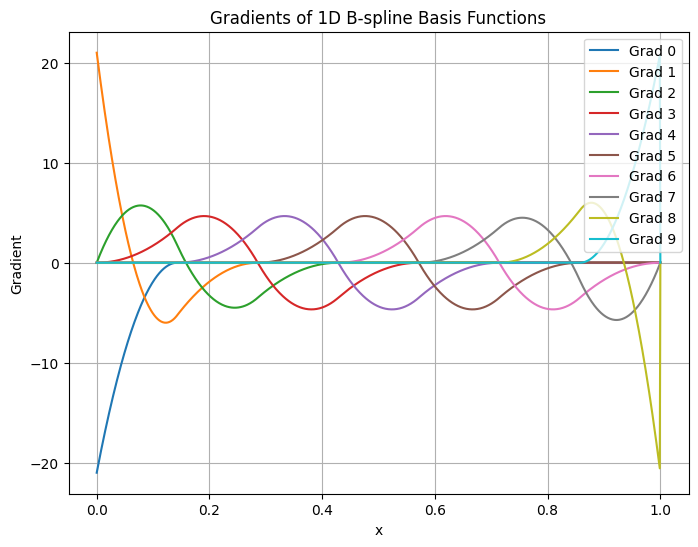

In [ ]:
basis.plot_1d_basis_gradients()